# Model Evaluation For Regression Tasks In Machine Learning

In this workshop we will learn how to recognize and address underfitting and overfitting in machine learning models. Whilst underfitting is quite easy to grasp overfitting is slightly more complex challenge.

---
# Underfitting
---

fundamentally your model is not predicting well in either the training data or the test data.


## Causes

Underfitting can occur when the model is too simple to capture the underlying patterns in the data. This can happen when:

- The model has too few parameters (e.g., a linear model for a non-linear problem).
- The model is not trained for enough iterations (e.g., early stopping).
- The features used for training are not informative enough.

High bias is a common characteristic of underfitting, where the model makes strong assumptions about the data and fails to capture its complexity.

## Detecting Underfitting

We can detect underfitting by evaluating the model's performance on both the training and test datasets. If the model performs poorly on both datasets, it is likely underfitting.

** we can also use learning curves to visualize the training and validation performance as a function of the training set size. If both curves converge to a high error, it indicates underfitting.

## Example of Underfitting

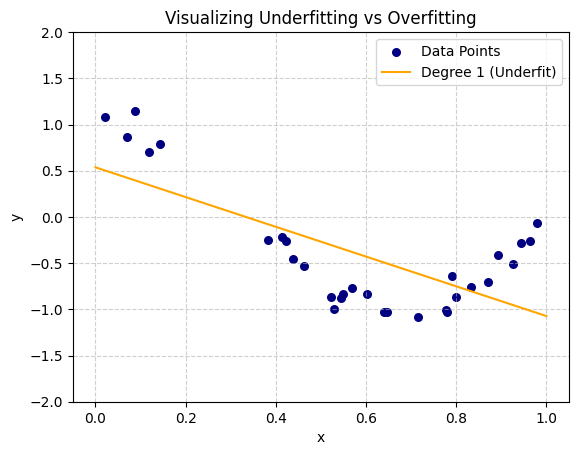

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

# 1. Generate a small, noisy dataset
np.random.seed(0)
n_samples = 30
X = np.sort(np.random.rand(n_samples))
# True function is a cosine wave + random noise
y = np.cos(1.5 * np.pi * X) + np.random.randn(n_samples) * 0.1

# X values for plotting the smooth curves
X_plot = np.linspace(0, 1, 100)

# 2. Create and fit models of different complexities
# Degree 1: A straight line (Underfitting)
model_underfit = make_pipeline(PolynomialFeatures(1), LinearRegression())
model_underfit.fit(X[:, np.newaxis], y)

# Degree 4: A balanced curve (Good Fit)
model_good = make_pipeline(PolynomialFeatures(4), LinearRegression())
model_good.fit(X[:, np.newaxis], y)

# Degree 15: Chasing the noise (Overfitting)
model_overfit = make_pipeline(PolynomialFeatures(15), LinearRegression())
model_overfit.fit(X[:, np.newaxis], y)

# 3. Visualization
plt.scatter(X, y, color='navy', s=30, label="Data Points")
plt.plot(X_plot, model_underfit.predict(X_plot[:, np.newaxis]), label="Degree 1 (Underfit)", color='orange')
#plt.plot(X_plot, model_good.predict(X_plot[:, np.newaxis]), label="Degree 4 (Good fit)", color='green')
#plt.plot(X_plot, model_overfit.predict(X_plot[:, np.newaxis]), label="Degree 15 (Overfit)", color='red')

plt.xlabel("x")
plt.ylabel("y")
plt.ylim(-2, 2)
plt.title("Visualizing Underfitting vs Overfitting")
plt.legend(loc="best")
plt.grid(True, linestyle='--', alpha=0.6)
plt.savefig('overfitting_plot.png')

From the above we can see that the model is not capturing the underlying pattern in the data, resulting in poor performance on both the training and test datasets. The model is too simple to capture the complexity of the data, leading to underfitting.

# How to address underfitting

to address underfitting, we can:

- Increase the model complexity by using a more complex algorithm or adding more features.
- Train the model for more iterations or epochs to allow it to learn more from the data.
- Use feature engineering to create more informative features that can help the model capture the underlying patterns in the data.


---
# Overfitting
---

Overfitting occurs when a model learns not only the underlying patterns in the training data but also the noise. This leads to a model that performs well on the training data but poorly on unseen test data, as it fails to generalize.

# Causes

Overfitting can be caused by:

- A model that is too complex (e.g., too many parameters or layers).
- Insufficient training data, which can lead the model to learn noise as if it were a pattern.
- Lack of regularization, which allows the model to fit the training data too closely***

# Detecting Overfitting

- we can detect overfitting by evaluating the model's performance on both the training and test datasets. If the model performs significantly better on the training data than on the test data, it is likely overfitting.
- we can also use learning curves to visualize the training and validation performance as a function of the training set size. If the training error continues to decrease while the validation error starts to increase, it indicates overfitting.

# Example of Overfitting

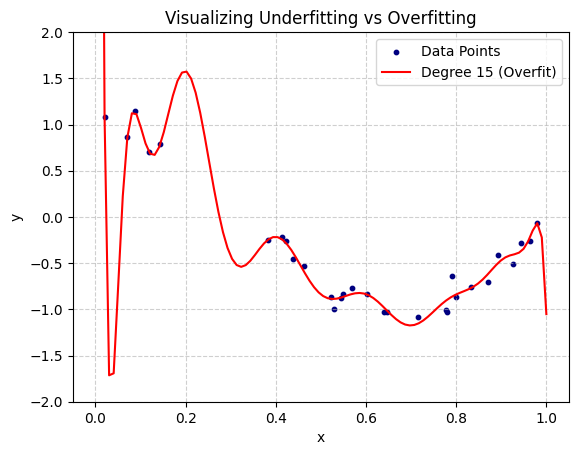

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

# 1. Generate a small, noisy dataset
np.random.seed(0)
n_samples = 30
X = np.sort(np.random.rand(n_samples))
# True function is a cosine wave + random noise
y = np.cos(1.5 * np.pi * X) + np.random.randn(n_samples) * 0.1

# X values for plotting the smooth curves
X_plot = np.linspace(0, 1, 100)

# 2. Create and fit models of different complexities
# Degree 1: A straight line (Underfitting)
model_underfit = make_pipeline(PolynomialFeatures(1), LinearRegression())
model_underfit.fit(X[:, np.newaxis], y)

# Degree 4: A balanced curve (Good Fit)
model_good = make_pipeline(PolynomialFeatures(4), LinearRegression())
model_good.fit(X[:, np.newaxis], y)

# Degree 15: Chasing the noise (Overfitting)
model_overfit = make_pipeline(PolynomialFeatures(15), LinearRegression())
model_overfit.fit(X[:, np.newaxis], y)

# 3. Visualization
plt.scatter(X, y, color='navy', s=10, label="Data Points")
#plt.plot(X_plot, model_underfit.predict(X_plot[:, np.newaxis]), label="Degree 1 (Underfit)", color='orange')
#plt.plot(X_plot, model_good.predict(X_plot[:, np.newaxis]), label="Degree 4 (Good fit)", color='green')
plt.plot(X_plot, model_overfit.predict(X_plot[:, np.newaxis]), label="Degree 15 (Overfit)", color='red')

plt.xlabel("x")
plt.ylabel("y")
plt.ylim(-2, 2)
plt.title("Visualizing Underfitting vs Overfitting")
plt.legend(loc="best")
plt.grid(True, linestyle='--', alpha=0.6)
plt.savefig('overfitting_plot.png')

# How to address overfitting

to address overfitting, we can:
- Reduce the model complexity by using a simpler algorithm or reducing the number of features.
- Increase the amount of training data to help the model learn more generalizable patterns.
- Use regularization techniques (e.g., L1 or L2 regularization) to penal
ize large coefficients and prevent the model from fitting the noise in the training data.

---
# Introducing Learning Curves
---

Learning curves offer a dynamic visual representation of a model's performance on both the training and validation datasets as the size of the training data increases. They are a powerful tool for diagnosing underfitting and overfitting.

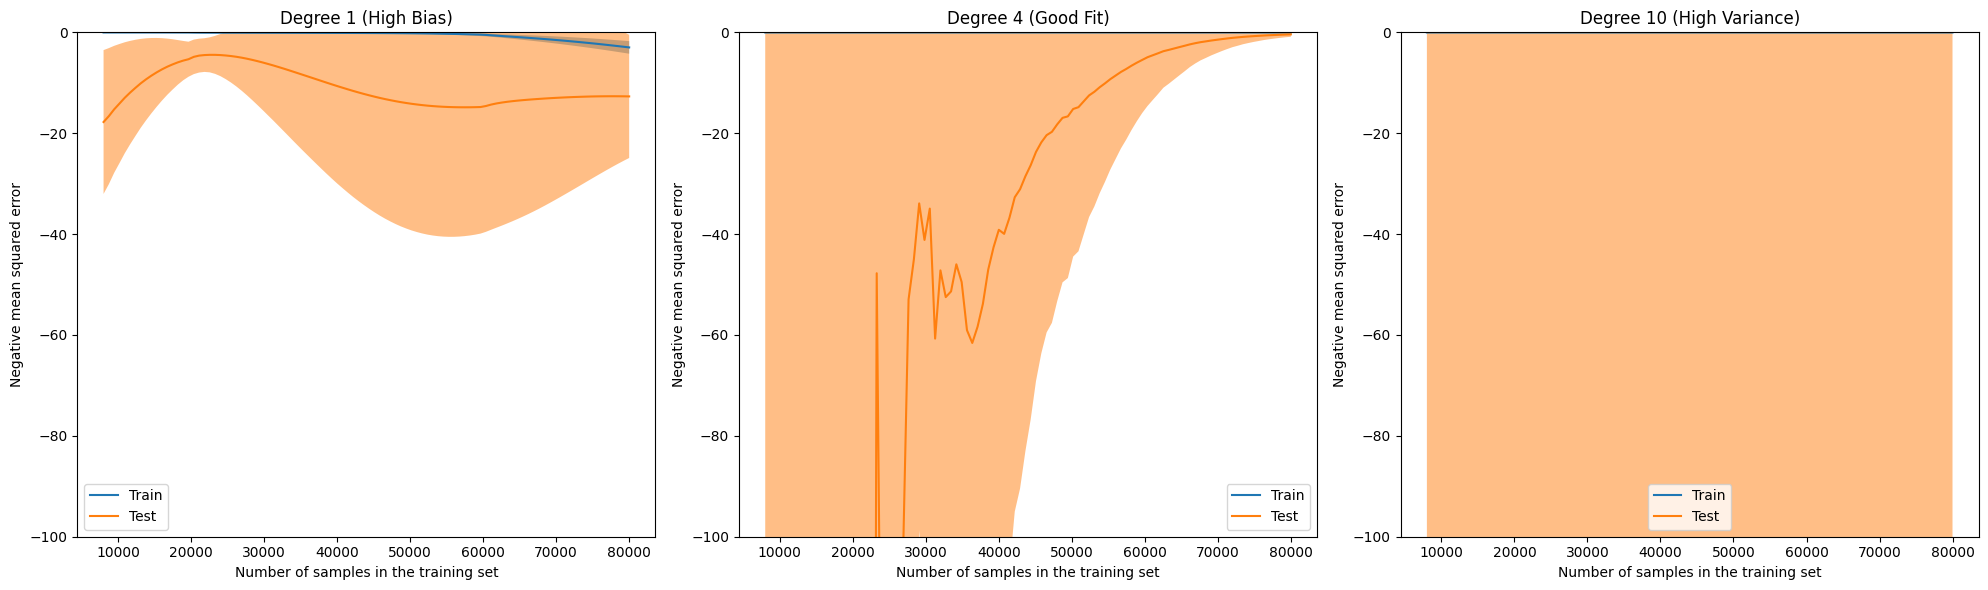

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import LearningCurveDisplay

# 1. DATA: 10,000 is plenty for a clear curve without crashing
np.random.seed(0)
n_samples = 100000
X = np.sort(np.random.rand(n_samples))
y = 4.5*np.cos(1.5 * np.pi * X) + np.random.randn(n_samples) * 0.1
X_reshaped = X[:, np.newaxis]

# 2. MODELS: Degree 15 is too heavy; Degree 10 still shows overfitting perfectly
model_underfit = make_pipeline(PolynomialFeatures(1), LinearRegression())
model_good = make_pipeline(PolynomialFeatures(4), LinearRegression())
model_overfit = make_pipeline(PolynomialFeatures(15), LinearRegression())

# 3. PLOTTING
fig, ax = plt.subplots(1, 3, figsize=(20, 6))
models = [model_underfit, model_good, model_overfit]
titles = ["Degree 1 (High Bias)", "Degree 4 (Good Fit)", "Degree 10 (High Variance)"]

for i, model in enumerate(models):
    LearningCurveDisplay.from_estimator(
        model, X_reshaped, y, cv=5, ax=ax[i],
        scoring="neg_mean_squared_error",
        std_display_style="fill_between",
        # 20 intervals is plenty for a smooth line
        train_sizes=np.linspace(0.1, 1.0, 100)
    )
    ax[i].set_title(titles[i])
    ax[i].set_ylim(-100, 0.01) # Zoom in so you can actually see the lines

plt.tight_layout()
plt.show()


---
# Bias-Variance Tradeoff
---

- Bias refers to the error introduced by approximating a real-world problem with a simplified model. High bias can lead to underfitting, where the model fails to capture the underlying patterns in the data.
- Variance refers to the error introduced by the model's sensitivity to small fluctuations in the training data. High variance can lead to overfitting, where the model captures noise in the training data as if it were a true pattern.

so, the bias-variance tradeoff is the balance between these two sources of error. A model with high bias and low variance may underfit the data, while a model with low bias and high variance may overfit the data. The goal is to find a model that achieves an optimal balance between bias and variance, resulting in good generalization performance on unseen data.

---
# Model Evaluation - Single Fold
---

In the example above I knew the degree of the polynomial that would underfit, fit well, and overfit. In real life we don't have this luxury. We need to use techniques like cross-validation to select the best hyperparameters for our model. This involves training multiple models with different hyperparameters and evaluating their performance on a validation set to find the best combination that minimizes overfitting and underfitting.

Lets choose our model based on the above example

In [ ]:
from sklearn.model_selection import train_test_split

# 1. DATA GENERATION
np.random.seed(42)
n_samples = 10000

# Complex sine + cosine wave
X = np.sort(np.random.rand(n_samples))
y = 2 * np.cos(4 * np.pi * X) + np.random.randn(n_samples) * 1.5
X_reshaped = X[:, np.newaxis]

# 2. THE SPLIT
# test_size=0.2 creates the 80/20 ratio (240 train, 60 test)
X_train, X_test, y_train, y_test = train_test_split(
    X_reshaped, y, test_size=0.2, random_state=42
)

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
import pandas as pd
import numpy as np

# 1. Instantiate the model only
lin_reg = LinearRegression()

# 2. Fit on the training data
# Note: X_train is already reshaped from our previous steps
lin_reg.fit(X_train, y_train)

# 3. Predict on both sets
y_train_pred = lin_reg.predict(X_train)
y_test_pred = lin_reg.predict(X_test)

# 4. Calculate RMSE
train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))

# 5. Display the baseline results
results = pd.DataFrame({
    "Metric": ["Train RMSE", "Test RMSE"],
    "Score": [train_rmse, test_rmse]
})
print(results)

       Metric     Score
0  Train RMSE  2.080036
1   Test RMSE  2.065562


---
# Model Evaluation - Cross Validation
---

though we can use a single train/test split to evaluate our model, our results can be highly dependent on how we split the data. Cross-validation is a technique that helps us get a more reliable estimate of our model's performance by averaging the results across multiple train/test splits.

In [ ]:
from sklearn.model_selection import cross_val_score

# 1. Run 5-fold cross-validation on the training set
# We use neg_root_mean_squared_error to stay in RMSE units
cv_scores = cross_val_score(
    lin_reg,
    X_train,
    y_train,
    scoring="neg_root_mean_squared_error",
    cv=10
)

# 2. Convert to positive RMSE
cv_rmse_scores = -cv_scores

pd.Series(cv_rmse_scores).describe()

count    10.000000
mean      2.080077
std       0.044306
min       2.020151
25%       2.058408
50%       2.073339
75%       2.093935
max       2.168354
dtype: float64

---
# Hyperparameter Tuning
---

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

# 1. Define the Pipeline
# We call the steps 'poly' and 'lin_reg'
full_pipeline = Pipeline([
    ("poly", PolynomialFeatures()),
    ("lin_reg", LinearRegression())
])

# 2. Define the Parameter Grid
# We will test degrees 1 through 10 to see where the error is lowest
param_grid = {
    'poly__degree': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    'poly__include_bias': [True, False]
}

# 3. Setup GridSearchCV
# We use the training data only (X_train, y_train)
grid_search = GridSearchCV(
    full_pipeline,
    param_grid,
    cv=10,
    scoring='neg_mean_squared_error',
    return_train_score=True
)

# 4. Fit to the training data
grid_search.fit(X_train, y_train)

# 5. Get the winning parameters
print(f"Best Degree: {grid_search.best_params_['poly__degree']}")
print(f"Include Bias: {grid_search.best_params_['poly__include_bias']}")
print(f"Best Score (Neg MSE): {grid_search.best_score_:.4f}")

Best Degree: 8
Include Bias: False
Best Score (Neg MSE): -2.2720


---
# Evaluate on the Test Set
---

In [ ]:
from sklearn.metrics import root_mean_squared_error

In [ ]:
final_model = grid_search.best_estimator_

In [ ]:
final_predictions = final_model.predict(X_test)
final_rmse = root_mean_squared_error(y_test, final_predictions)
print(final_rmse)

1.5360213332956287


---
# Getting a Confidence Interval for our Test Set Performance
---

In [ ]:
from scipy import stats

def rmse(squared_errors):
    return np.sqrt(np.mean(squared_errors))

confidence = 0.95
squared_errors = (final_predictions - y_test) ** 2


boot_result = stats.bootstrap([squared_errors], rmse,
                              confidence_level=confidence, random_state=42)
rmse_lower, rmse_upper = boot_result.confidence_interval

In [ ]:
rmse_lower, rmse_upper

(np.float64(1.4887384556424827), np.float64(1.5888576470606466))